In [1]:
# Install PyTorch Geometric
!pip install -q torch-geometric

In [8]:
import torch
from torch_geometric.datasets import KarateClub

dataset = KarateClub()
print(f'Dataset: {dataset}:')
print('======================')
print(f'Number of graphs: {len(dataset)}')
print(f'Number of features: {dataset.num_features}')
print(f'Number of classes: {dataset.num_classes}')

data = dataset[0]  # Get the first graph object.
print(data)
print('=============================================================')

# Gather some statistics about the graph.
print(f'Number of nodes: {data.num_nodes}')
print(f'Number of edges: {data.num_edges}')
print(f'Average node degree: {data.num_edges / data.num_nodes:.2f}')
print(f'Has isolated nodes: {data.has_isolated_nodes()}')
print(f'Has self-loops: {data.has_self_loops()}')
print(f'Is undirected: {data.is_undirected()}')

Dataset: KarateClub():
Number of graphs: 1
Number of features: 34
Number of classes: 4
Data(x=[34, 34], edge_index=[2, 156], y=[34], train_mask=[34])
Number of nodes: 34
Number of edges: 156
Average node degree: 4.59
Has isolated nodes: False
Has self-loops: False
Is undirected: True


In [6]:
import torch
import torch.nn.functional as F
from torch_geometric.datasets import KarateClub
from torch_geometric.nn import GCNConv

# Explicitly load dataset inside this cell to avoid scoping NameError
dataset = KarateClub()
data = dataset[0]

class GCN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        torch.manual_seed(1234)
        self.conv1 = GCNConv(dataset.num_features, 4)
        self.conv2 = GCNConv(4, 4)
        self.conv3 = GCNConv(4, 2)  # Dimension 2 for 2D visualization
        self.classifier = torch.nn.Linear(2, dataset.num_classes)

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index)
        h = torch.tanh(h)
        h = self.conv2(h, edge_index)
        h = torch.tanh(h)
        h = self.conv3(h, edge_index)
        h = torch.tanh(h)  # Final GNN embedding space

        # Classifier layer
        out = self.classifier(h)

        return out, h

model = GCN()
print(model)

GCN(
  (conv1): GCNConv(34, 4)
  (conv2): GCNConv(4, 4)
  (conv3): GCNConv(4, 2)
  (classifier): Linear(in_features=2, out_features=4, bias=True)
)


In [7]:
import time
import matplotlib.pyplot as plt

# Instantiate model, criterion, and optimizer using the loaded data
model = GCN()
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

def train(data):
    model.train()
    optimizer.zero_grad()
    out, h = model(data.x, data.edge_index)
    loss = criterion(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss, h

losses = []
embeddings = []

for epoch in range(401):
    loss, h = train(data)
    losses.append(loss.item())
    # Keep track of embeddings for visualization
    if epoch % 10 == 0:
        embeddings.append((epoch, h.detach().numpy()))
    if epoch % 50 == 0:
        print(f'Epoch: {epoch:03d}, Loss: {loss:.4f}')

Epoch: 000, Loss: 1.4324
Epoch: 050, Loss: 0.5663
Epoch: 100, Loss: 0.1817
Epoch: 150, Loss: 0.1023
Epoch: 200, Loss: 0.0693
Epoch: 250, Loss: 0.0515
Epoch: 300, Loss: 0.0405
Epoch: 350, Loss: 0.0331
Epoch: 400, Loss: 0.0279


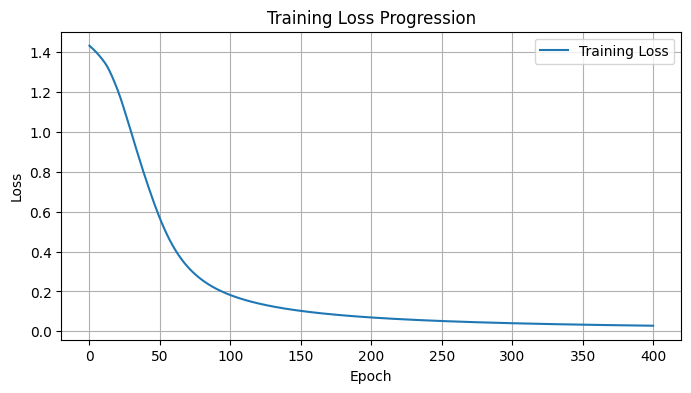

In [9]:
# Plot Training Loss
plt.figure(figsize=(8, 4))
plt.plot(losses, label='Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss Progression')
plt.grid(True)
plt.legend()
plt.show()

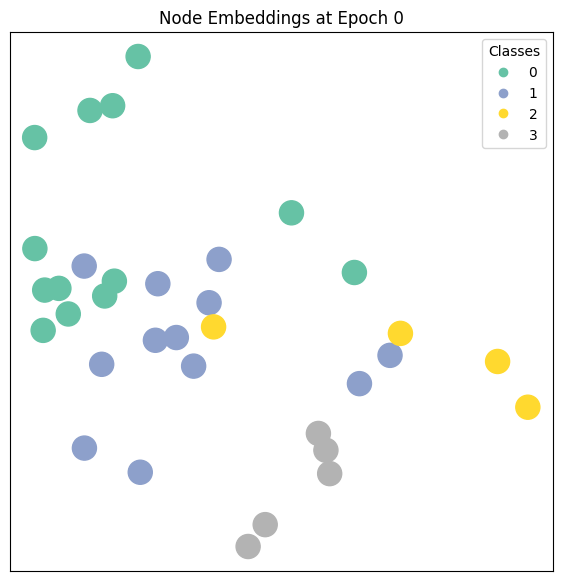

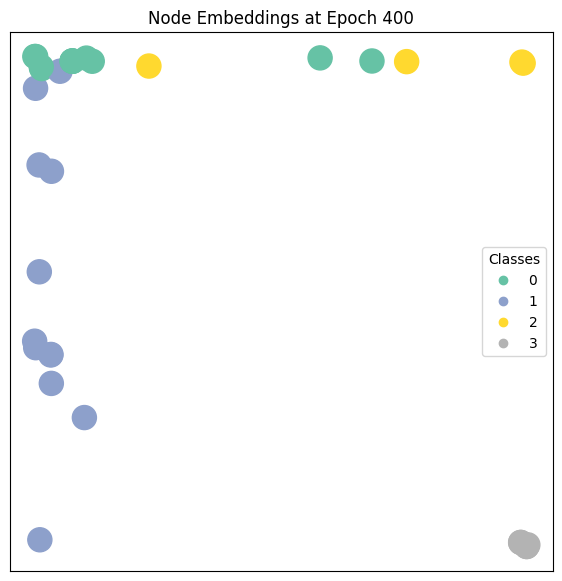

In [10]:
# Visualize Node Embeddings in 2D space
import numpy as np

def plot_embeddings(epoch, h_embeddings, y_labels):
    plt.figure(figsize=(7, 7))
    plt.xticks([])
    plt.yticks([])
    classes = len(np.unique(y_labels))
    scatter = plt.scatter(h_embeddings[:, 0], h_embeddings[:, 1], s=300, c=y_labels, cmap="Set2")
    plt.legend(*scatter.legend_elements(), title="Classes")
    plt.title(f'Node Embeddings at Epoch {epoch}')
    plt.show()

# Visualize initial and final states
plot_embeddings(embeddings[0][0], embeddings[0][1], data.y.numpy())
plot_embeddings(embeddings[-1][0], embeddings[-1][1], data.y.numpy())